# Peaks in and out of the powder: the sparse pixels of a scan put through the same matrix

chunk2sparseCSC gives, for every frame, the powder of all the unmasked pixels and the sparse pixels
above the cut.  The powder of the sparse pixels alone is the same matrix product on them, so
powder - peaks is the powder of what is left below the cut: the Bragg spots stripped out.  No
kernel of ours is needed for it: the sparse pixels are few, and one scipy product does a whole scan.

The sparse pixels are kept here as ImageD11's SparseScan holds them (row, col, intensity, nnz per
frame and ipt, the pointer to the first pixel of each frame).  For scipy they are one sparse matrix
of nframes rows, each row one frame flattened to ni*nj columns: column = row*nj + col, and ipt is
its row pointer.  Then peaks = S @ M.T, (nframes, nbins), with M the (nbins, ni*nj) matrix that made
the powder.  With a fixed_point_matrix, M = fixed.to_scipy() holds its integer weights: the powder and
the peaks are int64 sums of the same products, and powder - peaks is exact.

In [1]:
import h5py
import hdf5plugin  # registers the bitshuffle filter, so that h5py can decompress too
import numpy as np
import pyFAI
import scipy.sparse
from pyFAI.method_registry import IntegrationMethod

import bslz4_to_sparse

In [2]:
h5filename = "eiger_0000.h5"  # your file: bitshuffle-compressed, one frame per chunk
h5dataset = "/entry_0000/ESRF-ID11/eiger/data"  # the (nframes, ni, nj) dataset inside it
mask_filename = (
    "mask.h5"  # your detector mask: a dataset "mask", pyFAI's convention (non-zero = masked)
)
poni_filename = "calib.poni"  # your pyFAI geometry
cut = 2  # keep pixels above 2 counts: for a sparse scan (silicon) these are the spots
nbins = 2000

In [3]:
with h5py.File(mask_filename, "r") as h5:
    bad = h5["mask"][()] != 0  # the masked pixels
mask = (~bad).astype(np.uint8)
ai = pyFAI.load(poni_filename)
method = IntegrationMethod.select_one_available(("bbox", "csc", "cython"), dim=1)
ones = ai.integrate1d(np.ones(bad.shape, np.float32), nbins, unit="q_nm^-1", method=method, mask=bad)
engine = ai.engines[method].engine  # pyFAI's CSC matrix
ni, nj = bad.shape
fixed = bslz4_to_sparse.fixed_point_matrix(engine, mask, np.uint16)  # integer weights, mask folded in
M = fixed.to_scipy()  # the same weights for scipy: (nbins, ni*nj), int64

One pass over the file: the powder of every frame and its sparse pixels, as a segmenter makes them.

In [4]:
row, col, intensity, nnz, powder = [], [], [], [], []
with h5py.File(h5filename, "r") as h5:
    ds = h5[h5dataset]
    assert ds.dtype == np.uint16 and ds.shape[1:] == (ni, nj)
    codec = bslz4_to_sparse.detect_codec(ds)  # bitshuffle with lz4 or zstd
    integ = bslz4_to_sparse.chunk2sparseCSC(mask, fixed, np.uint16, codec)
    nframes = ds.shape[0]
    for i in range(nframes):
        npx, (values, indices), powder_sum = integ(ds.id.read_direct_chunk((i, 0, 0))[1], cut)
        row.append((indices[:npx] // nj).astype(np.uint16))
        col.append((indices[:npx] % nj).astype(np.uint16))
        intensity.append(values[:npx].copy())
        nnz.append(npx)
        powder.append(powder_sum.copy())  # the object's array is overwritten by the next call
row, col, intensity = np.concatenate(row), np.concatenate(col), np.concatenate(intensity)
nnz, powder = np.array(nnz), np.array(powder)
ipt = np.concatenate(([0], np.cumsum(nnz)))  # SparseScan.ipt
print("%d frames, %d pixels above %d counts (%.0f per frame)" % (nframes, ipt[-1], cut, nnz.mean()))

250 frames, 59113 pixels above 2 counts (236 per frame)


The sparse pixels as one matrix (nframes, ni*nj), and their powder: one call for the whole scan.

In [5]:
flat = row.astype(np.int64) * nj + col
S = scipy.sparse.csr_matrix((intensity.astype(np.int64), flat, ipt), shape=(nframes, ni * nj))
peaks = (S @ M.T).toarray()  # (nframes, nbins), int64
stripped = powder - peaks  # the powder of the pixels at or below the cut, int64
print("fraction of the scan's signal in the sparse pixels: %.3f" % (peaks.sum() / powder.sum()))

fraction of the scan's signal in the sparse pixels: 0.208


Only the sum over the scan is wanted?  Then the pixels go into one flattened frame first.

In [6]:
summed = np.bincount(flat, weights=intensity, minlength=ni * nj).astype(np.int64)
assert np.array_equal(M @ summed, peaks.sum(axis=0))

Check: stripped is the powder of the same frames with the sparse pixels set to zero.

In [7]:
nchk = min(nframes, 5)
with h5py.File(h5filename, "r") as h5:
    frames = h5[h5dataset][:nchk].reshape(nchk, ni * nj)
frames[np.repeat(np.arange(nchk), nnz[:nchk]), flat[: ipt[nchk]]] = 0
_, _, below = integ.from_frames(frames, cut)
assert np.array_equal(stripped[:nchk], below)
print("stripped equals the powder of the first %d frames without their sparse pixels" % nchk)

stripped equals the powder of the first 5 frames without their sparse pixels


A picture: the scan's powder, the part in the sparse pixels and what is left, each divided by
the pixels in its bin (sum_normalization) to be an intensity; integers / scale are the float sums.

In [8]:
import matplotlib.pyplot as plt

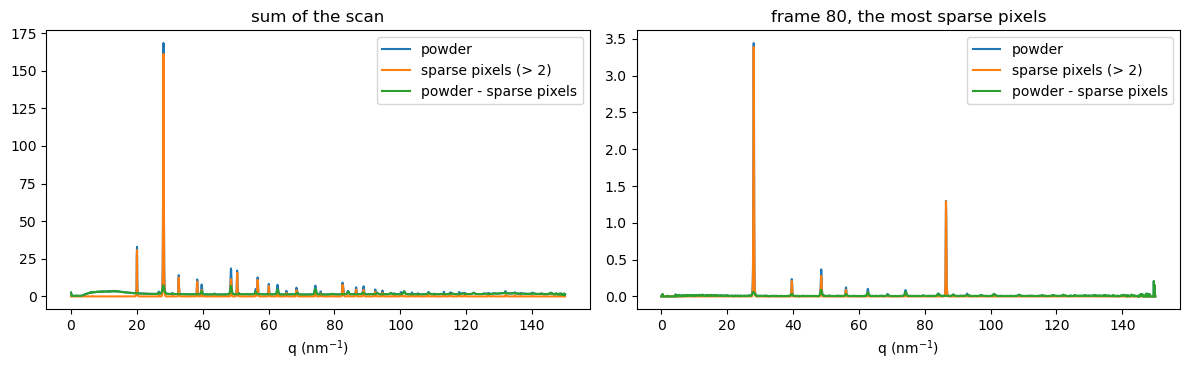

In [9]:
norm = np.asarray(ones.sum_normalization).ravel()
inten = lambda s: np.divide(s / fixed.scale, norm, out=np.zeros(nbins), where=norm > 0)
q = ones.radial
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
busiest = int(np.argmax(nnz))
for ax, pick, title in (
    (axes[0], lambda a: a.sum(axis=0), "sum of the scan"),
    (axes[1], lambda a: a[busiest], "frame %d, the most sparse pixels" % busiest),
):
    ax.plot(q, inten(pick(powder)), label="powder")
    ax.plot(q, inten(pick(peaks)), label="sparse pixels (> %d)" % cut)
    ax.plot(q, inten(pick(stripped)), label="powder - sparse pixels")
    ax.set_xlabel("q (nm$^{-1}$)")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()